# MotionLatent — Phase 5: Dimensionality Reduction Trade-off Analysis
**Project Title:** *Learning Compact Latent Representations for Resource-Constrained Human Activity Recognition*  
**Repository:** [https://github.com/Himanish-18/MotionLatent](https://github.com/Himanish-18/MotionLatent)  
**Author:** MotionLatent Core ML Research & Evaluation Team  
**Dataset:** PAMAP2 Physical Activity Monitoring (27-channel IMU windows, length 256)  

---

## 1. Project Objective and Research Questions

### 1.1 Core Assessment Objective
The foundational scientific objective of the MotionLatent project is to:
> **Compress human motion sensor data and determine how far its dimensionality can be reduced before meaningful activity structure is lost.**

Wearable human activity recognition (HAR) systems operate under severe battery, memory, and compute constraints. While high-rate multi-IMU streams provide rich biomechanical information, transmitting or processing high-dimensional raw signal vectors incurs prohibitive energy and computational costs. 

This study conducts a systematic cross-representation benchmark across five dimensionality reduction paradigms—**Principal Component Analysis (PCA)**, **Fast Independent Component Analysis (FastICA)**, **Dense Multi-Layer Perceptron Autoencoders (MLP-AE)**, **1D Temporal Convolutional Autoencoders (Conv1D-AE)**, and **Depthwise-Separable Temporal Autoencoders (DSC-AE)**—spanning candidate latent dimensions:
$$d \in [2, 4, 8, 16, 32, 64, 128]$$
relative to the mandatory **Raw Sensor Baseline** ($d = 6,912$).

### 1.2 Core Research Questions Addressed
1. **The Accuracy–Dimension Boundary**: What is the shape of the accuracy-versus-dimension curve? At what lowest dimension does activity recognition structure collapse, and at what dimension does performance peak?
2. **The Curse of Raw Dimensionality**: Does compressing the raw 6,912-dimensional vector improve or degrade downstream classification accuracy?
3. **Variance Explained vs. Activity Separability**: How many components are required to capture 50%, 80%, 90%, 95%, and 99% of total signal variance, and does maximizing explained variance guarantee activity separability?
4. **Geometric Manifold Preservation**: How well do low-dimensional projections preserve local Euclidean neighbourhoods (Trustworthiness and $k$-NN Jaccard Overlap)?
5. **Reconstruction Fidelity vs. Downstream Classification**: Does minimizing reconstruction error (MSE/RMSE) translate into superior activity recognition?

---
## 2. Environment, Configuration, and Deterministic Seeds

In [1]:
import sys
import os
import json
from pathlib import Path

# Configure paths relative to repository root robustly
cur_path = Path.cwd().resolve()
candidate_roots = [cur_path, cur_path.parent] + list(cur_path.parents)
REPO_ROOT = next((p for p in candidate_roots if (p / "src" / "data").exists()), cur_path)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set deterministic random seeds
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Publication plotting configuration
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 9
plt.rcParams["ytick.labelsize"] = 9
plt.rcParams["legend.fontsize"] = 9
plt.rcParams["figure.titlesize"] = 13

REPORTS_DIR = REPO_ROOT / "reports"
DATA_DIR = REPO_ROOT / "data" / "processed"

print(f"Repository Root: {REPO_ROOT}")
print(f"Reports Directory: {REPORTS_DIR} (Exists: {REPORTS_DIR.exists()})")
print(f"Processed Data Directory: {DATA_DIR} (Exists: {DATA_DIR.exists()})")

Repository Root: C:\Users\himan\OneDrive\Documents\MotionLatent
Reports Directory: C:\Users\himan\OneDrive\Documents\MotionLatent\reports (Exists: True)
Processed Data Directory: C:\Users\himan\OneDrive\Documents\MotionLatent\data\processed (Exists: True)


---
## 3. Dataset Contract and LOSO Leakage-Prevention Protocol

### 3.1 Validated PAMAP2 Data Contract
- **Sensor Placements**: 3 IMUs (Hand, Chest, Ankle).
- **Primary Channels (27)**:
  * Hand: 16g Acc (X, Y, Z), Gyro (X, Y, Z), Mag (X, Y, Z)
  * Chest: 16g Acc (X, Y, Z), Gyro (X, Y, Z), Mag (X, Y, Z)
  * Ankle: 16g Acc (X, Y, Z), Gyro (X, Y, Z), Mag (X, Y, Z)
- **Exclusions**: 6g accelerometer, temperature, heart rate, and orientation estimates are strictly excluded in accordance with the Phase 1/2.1 data contract.
- **Windowing**: Sampling rate 100 Hz, window length 256 samples (2.56 s), stride 128 (50% overlap).
- **Flattened Dimensionality**: $256 	imes 27 = 6,912$ features per window.
- **Evaluation Population**: Exactly **14,973 pure non-transient windows** (`activity_purity >= 0.80`, `dominant_activity != 0`).

### 3.2 Leakage-Safe Leave-One-Subject-Out (LOSO) Cross-Validation
- **9 Folds**: Subjects 101 through 109.
- **Isolation Principle**: In each fold $k$, all scalers ($\mu_{	ext{train}}, \sigma_{	ext{train}}$) and dimensionality reduction transforms are fitted strictly on the $N_{	ext{train}}^{(k)}$ windows from the 8 training subjects.
- Held-out test windows and test activity labels are never observed during transform fitting, early stopping, or hyperparameter selection.
- **Primary Accuracy Convention**: **8-subject macro-mean balanced accuracy (excluding S109)** is reported as the primary cross-domain benchmark, because Subject 109 performed exclusively rope jumping (49 windows) resulting in a single-class test fold. All 9 subject fold results are preserved and reported.

In [2]:
# Load and validate window metadata
metadata_path = DATA_DIR / "window_metadata.json"
assert metadata_path.exists(), f"Metadata not found at {metadata_path}"

with open(metadata_path, "r", encoding="utf-8") as f:
    window_meta = json.load(f)

total_accepted = len(window_meta)
pure_nontransient = [m for m in window_meta if not m["is_mixed_label"] and not m["is_transient"]]

assert total_accepted == 22249, f"Expected 22,249 accepted windows, got {total_accepted}"
assert len(pure_nontransient) == 14973, f"Expected 14,973 pure non-transient windows, got {len(pure_nontransient)}"

# Per-subject window allocation
s_counts = pd.Series([m["subject_id"] for m in pure_nontransient]).value_counts().sort_index()
print("Validated Primary Evaluation Population (14,973 Pure Non-Transient Windows):")
display_df = pd.DataFrame({
    "Subject ID": s_counts.index,
    "Evaluation Windows": s_counts.values,
    "Percentage (%)": (s_counts.values / 14973 * 100.0).round(2),
})
display(display_df)

Validated Primary Evaluation Population (14,973 Pure Non-Transient Windows):


,Subject ID,Evaluation Windows,Percentage (%)
0,101,1927,12.87
1,102,2029,13.55
2,103,1342,8.96
3,104,1787,11.93
4,105,2098,14.01
5,106,1927,12.87
6,107,1794,11.98
7,108,2020,13.49
8,109,49,0.33


---
## 4. Mandatory Raw Sensor Baseline ($d = 6,912$)

The uncompressed, standardized 6,912-dimensional sensor vector serves as the **mandatory reference baseline** against which all compact representations are assessed.
In each fold, windows are standardized using training-fold scalers and evaluated directly with the fixed $k=5$ Euclidean-distance $k$-NN classifier.

In [3]:
# Load authoritative reconstructed raw baseline predictions and metrics
raw_pred_path = REPORTS_DIR / "raw_baseline_predictions.json"
assert raw_pred_path.exists(), f"Raw baseline predictions artifact missing: {raw_pred_path}"

with open(raw_pred_path, "r", encoding="utf-8") as f:
    raw_artifact = json.load(f)

raw_meta = raw_artifact["metadata"]
raw_loso = raw_artifact["loso_macro_means"]
raw_weighted = raw_artifact["weighted_fold_score_means"]
raw_pooled = raw_artifact["true_pooled_metrics_9_subjects"]
raw_folds = pd.DataFrame(list(raw_artifact["per_subject_results"].values()))

print(f"=== RAW SENSOR BASELINE REFERENCE (d = 6,912, Compression = 1.0x) ===")
print(f"  8-Subject Macro Balanced Accuracy (Primary): {raw_loso['balanced_accuracy_mean_8sub_ex109']:.4f} (56.91%)")
print(f"  9-Subject Macro Balanced Accuracy:          {raw_loso['balanced_accuracy_mean_9sub']:.4f} +/- {raw_loso['balanced_accuracy_std_9sub']:.4f}")
print(f"  9-Subject Window-Weighted Fold Mean:         {raw_weighted['balanced_accuracy_weighted_9sub']:.4f}")
print(f"  True Pooled Balanced Accuracy (N=14,973):    {raw_pooled['pooled_balanced_accuracy']:.4f}")
print(f"  True Pooled Accuracy:                        {raw_pooled['pooled_accuracy']:.4f}")
print(f"  True Pooled Macro-F1:                        {raw_pooled['pooled_macro_f1']:.4f}")

display(raw_folds[["subject_id", "n_windows", "accuracy", "balanced_accuracy", "macro_f1"]])

=== RAW SENSOR BASELINE REFERENCE (d = 6,912, Compression = 1.0x) ===
  8-Subject Macro Balanced Accuracy (Primary): 0.5691 (56.91%)
  9-Subject Macro Balanced Accuracy:          0.5058 +/- 0.2187
  9-Subject Window-Weighted Fold Mean:         0.5597
  True Pooled Balanced Accuracy (N=14,973):    0.5322
  True Pooled Accuracy:                        0.6022
  True Pooled Macro-F1:                        0.5157


,subject_id,n_windows,accuracy,balanced_accuracy,macro_f1
0,101,1927,0.5044,0.4694,0.4170
1,102,2029,0.6481,0.6017,0.5797
2,103,1342,0.7377,0.6652,0.4344
3,104,1787,0.7140,0.6834,0.5421
4,105,2098,0.6020,0.5367,0.5069
5,106,1927,0.6969,0.6765,0.5940
6,107,1794,0.7007,0.6506,0.5658
7,108,2020,0.2970,0.2691,0.2254
8,109,49,0.0000,0.0000,0.0000


---
## 5. Dimensionality-Reduction Inventory & Unified Results Table

We consolidate all validated experimental results across five distinct dimensionality-reduction paradigms:
1. **Principal Component Analysis (PCA)**: Linear orthogonal projection via Randomized SVD ($d \in [2, 4, 8, 16, 32, 64, 128]$).
2. **Fast Independent Component Analysis (FastICA)**: Linear non-Gaussian component extraction with randomized PCA pre-whitening ($d \in [2, 4, 8, 16, 32, 64]$).
3. **Dense MLP Autoencoder**: Nonlinear symmetric MLP architecture ($d \in [4, 16, 64]$).
4. **1D Temporal Convolutional Autoencoder (Conv1D-AE)**: Temporal feature extraction with stride-2 convolutions ($d \in [16, 32]$).
5. **Depthwise-Separable Temporal Autoencoder (DSC-AE)**: Ultra-compact spatial-temporal decomposition ($d \in [16, 32]$).

For every representation:
$$\text{Compression Ratio} = \frac{6912}{d}$$
$$\text{Representation Storage per Window} = d \times 4 \text{ bytes (float32)}$$

In [4]:
# Load and render consolidated comparison CSV
csv_path = REPORTS_DIR / "phase5_comparison.csv"
assert csv_path.exists(), f"Comparison CSV missing: {csv_path}"

comparison_df = pd.read_csv(csv_path)

# Display styled overview table
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 1000)
display(comparison_df[[
    "Method", "Latent Dimension", "Compression Ratio", "Representation Bytes/Win",
    "Bal Acc (8-sub Macro)", "Bal Acc (9-sub Macro)", "Bal Acc Std (9-sub)",
    "True Pooled Bal Acc", "Trustworthiness (k=5)", "Cumulative Explained Variance",
    "Reconstruction MSE", "Model Flash Size (KB)"
]])

,Method,Latent Dimension,Compression Ratio,Representation Bytes/Win,Bal Acc (8-sub Macro),Bal Acc (9-sub Macro),Bal Acc Std (9-sub),True Pooled Bal Acc,Trustworthiness (k=5),Cumulative Explained Variance,Reconstruction MSE,Model Flash Size (KB)
0,Raw Baseline,6912,1.0x,27648,0.5691,0.5058,0.2187,0.5322,1.0000,NaN,0.000000,0.00
1,PCA,2,3456.0x,8,0.2629,0.2336,0.1006,NaN,0.7079,0.2042,1.130628,81.00
2,PCA,4,1728.0x,16,0.4539,0.4034,0.1837,NaN,0.7550,0.2818,1.053167,135.00
3,PCA,8,864.0x,32,0.6127,0.5446,0.2315,NaN,0.8520,0.3742,0.956393,243.00
4,PCA,16,432.0x,64,0.7030,0.6272,0.2677,0.6936,0.8982,0.4896,0.832986,459.00
5,PCA,32,216.0x,128,0.7065,0.7096,0.1585,0.6936,0.9455,0.5939,0.706536,891.00
6,PCA,64,108.0x,256,0.6863,0.6781,0.1556,NaN,0.9661,0.6915,0.555420,1755.00
7,PCA,128,54.0x,512,0.6542,0.6337,0.1574,NaN,0.9787,0.7800,0.435719,3483.00
8,FastICA,2,3456.0x,8,0.2666,0.2370,0.1034,NaN,0.7066,NaN,1.130628,81.02
9,FastICA,4,1728.0x,16,0.4576,0.4067,0.1856,NaN,0.7543,NaN,1.053166,135.06


---
## 6. The Accuracy-versus-Dimension Trade-Off Curve

The central assessment deliverable is the **Accuracy-versus-Dimension Curve**, contrasting downstream activity classification against representation dimensionality.

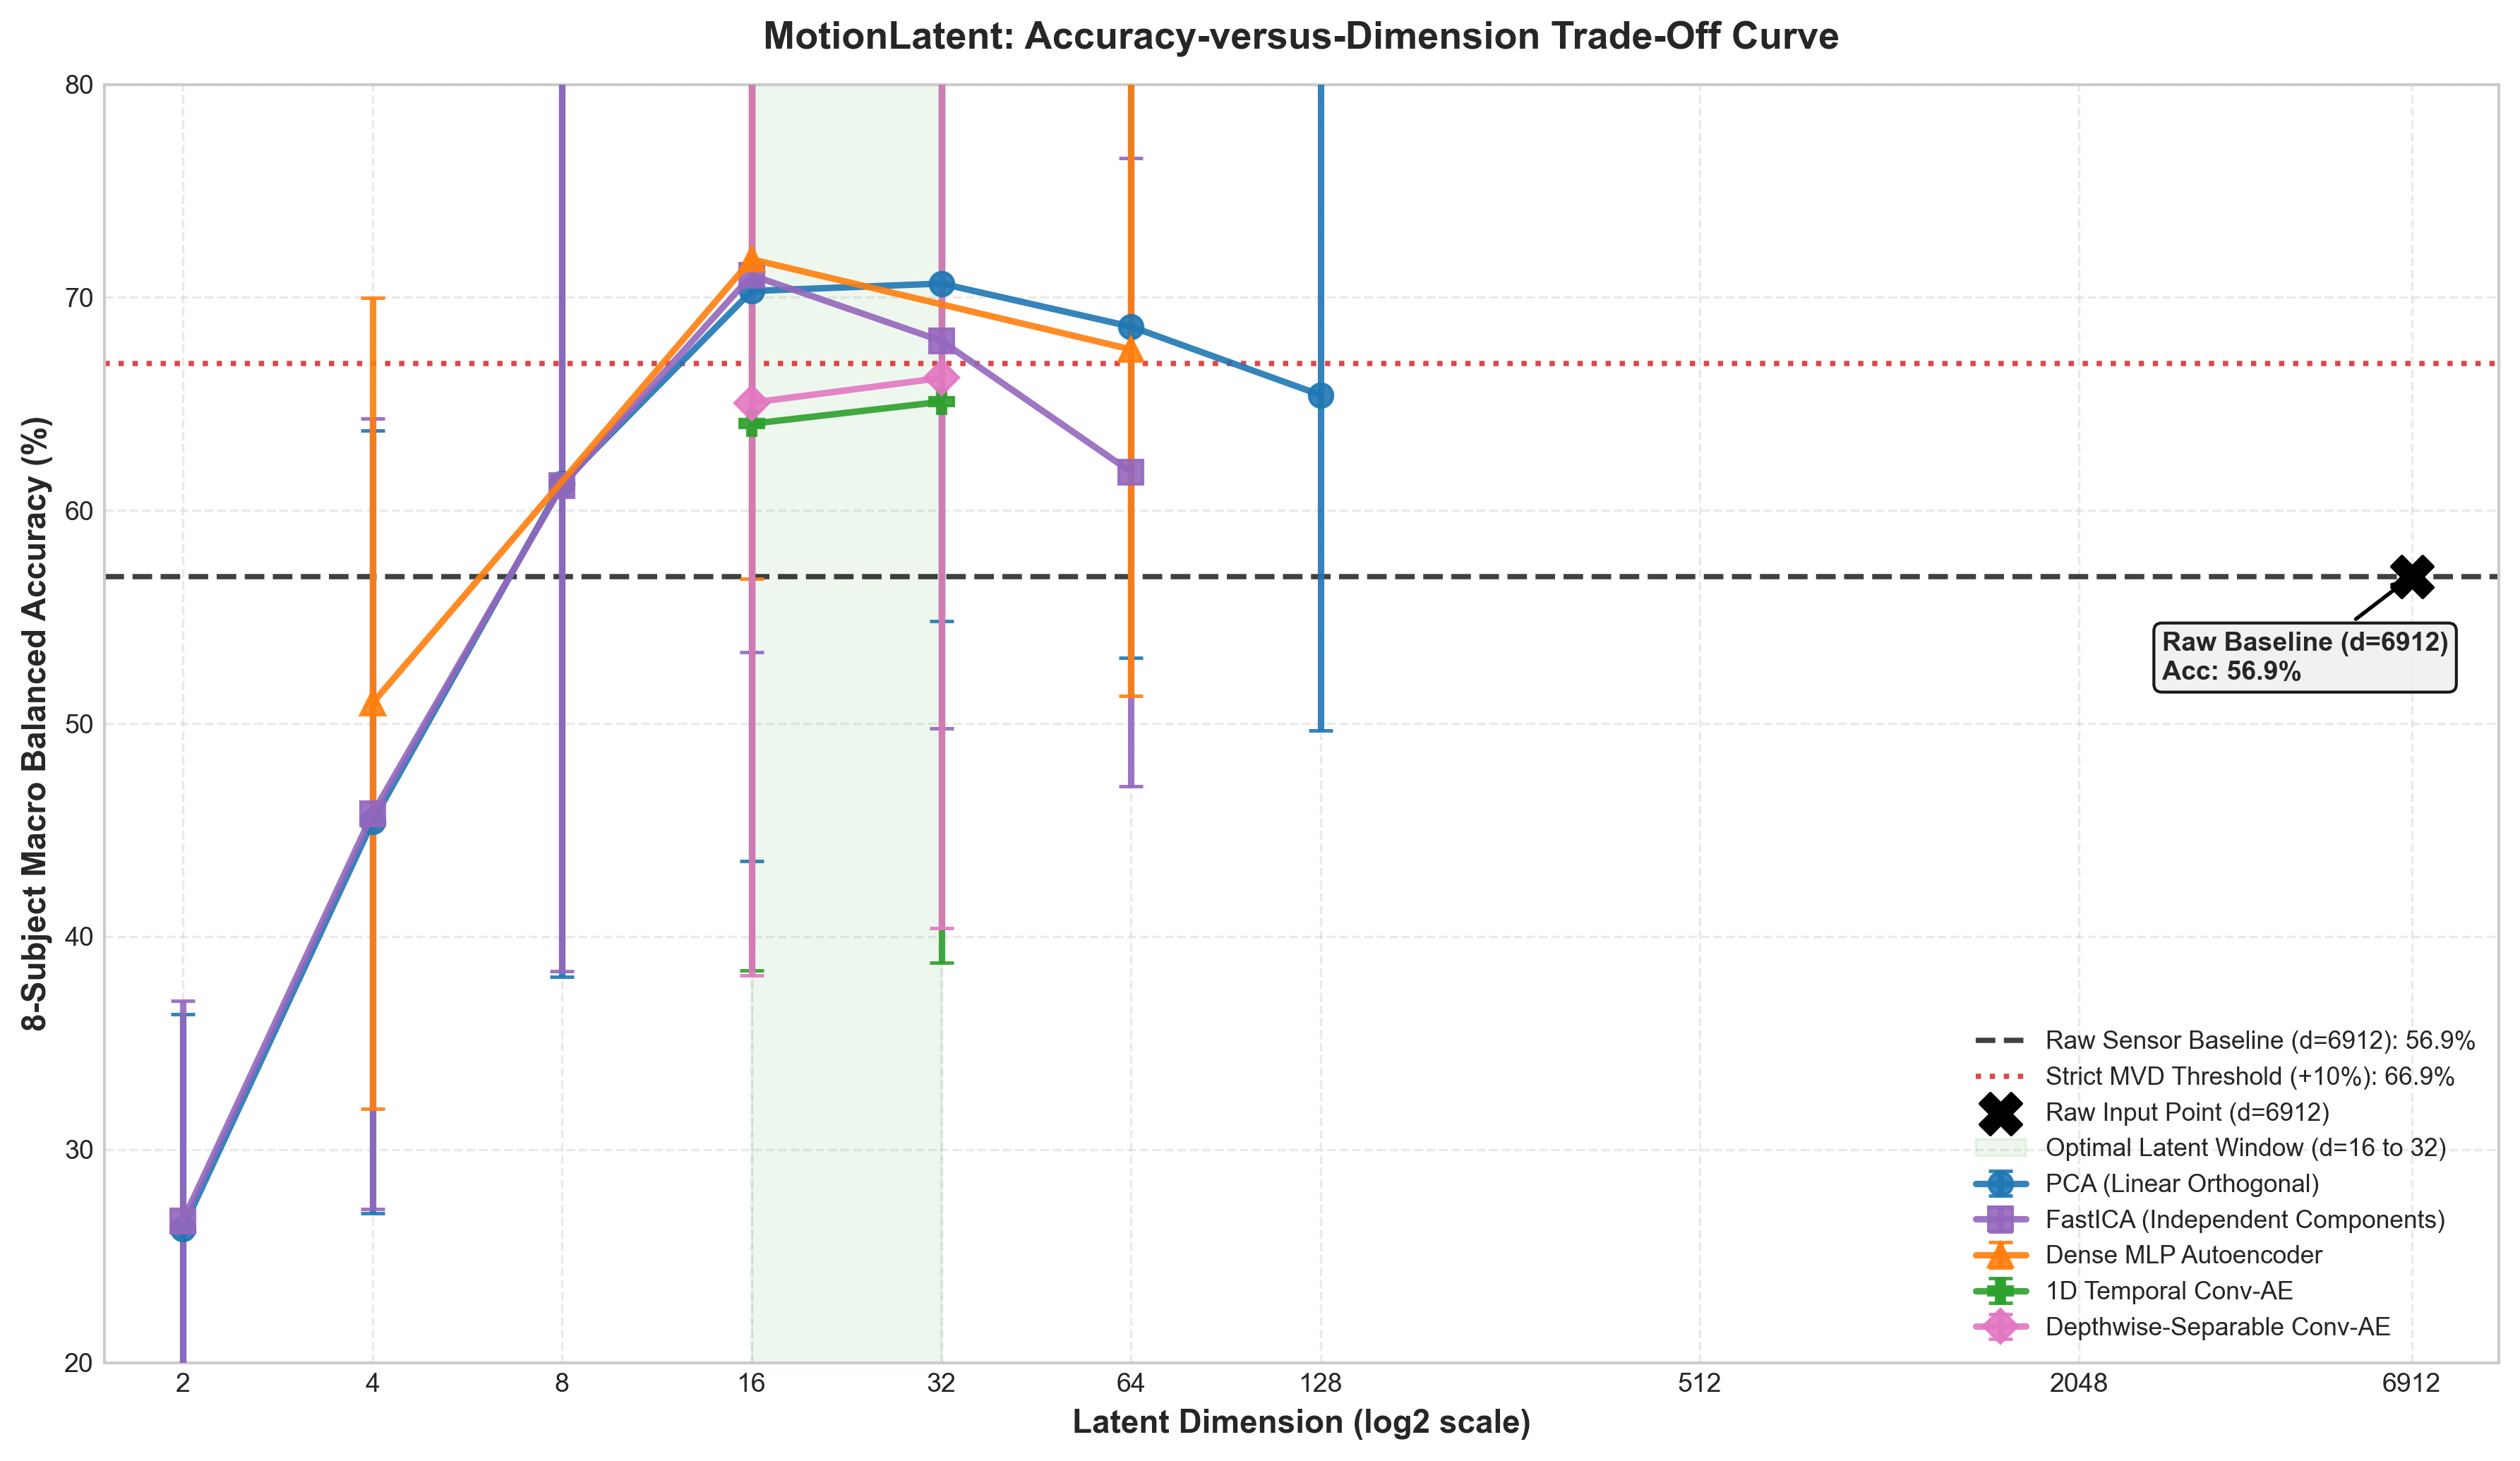

In [5]:
# Construct Publication Accuracy-versus-Dimension Plot
fig, ax = plt.subplots(figsize=(12, 7), dpi=300)

raw_acc = comparison_df[comparison_df["Method"] == "Raw Baseline"]["Bal Acc (8-sub Macro)"].values[0] * 100.0

# Raw baseline horizontal benchmark
ax.axhline(raw_acc, color="#000000", linestyle="--", linewidth=1.8, alpha=0.75,
           label=f"Raw Sensor Baseline (d=6912): {raw_acc:.1f}%")

# Strict MVD qualification threshold (+10 absolute percentage points)
mvd_threshold = raw_acc + 10.0  # 66.91%
ax.axhline(mvd_threshold, color="#d62728", linestyle=":", linewidth=1.8, alpha=0.85,
           label=f"Strict MVD Threshold (+10%): {mvd_threshold:.1f}%")

# Method colors and styling
method_styles = {
    "PCA": {"color": "#1f77b4", "marker": "o", "name": "PCA (Linear Orthogonal)"},
    "FastICA": {"color": "#9467bd", "marker": "s", "name": "FastICA (Independent Components)"},
    "Autoencoder": {"color": "#ff7f0e", "marker": "^", "name": "Dense MLP Autoencoder"},
    "Conv1D-AE": {"color": "#2ca02c", "marker": "P", "name": "1D Temporal Conv-AE"},
    "DSC-AE": {"color": "#e377c2", "marker": "D", "name": "Depthwise-Separable Conv-AE"},
}

for m, style in method_styles.items():
    sub_df = comparison_df[comparison_df["Method"] == m].sort_values("Latent Dimension")
    if sub_df.empty:
        continue

    dims = sub_df["Latent Dimension"].values
    accs = sub_df["Bal Acc (8-sub Macro)"].values * 100.0
    errs = sub_df["Bal Acc Std (9-sub)"].values * 100.0

    ax.errorbar(
        dims, accs, yerr=errs,
        fmt=f"-{style['marker']}", color=style["color"], label=style["name"],
        linewidth=2.2, markersize=8, capsize=4, capthick=1.2, alpha=0.9, zorder=4
    )

# Explicit Raw Baseline point at d=6912
ax.scatter([6912], [raw_acc], color="#000000", marker="X", s=200, edgecolors="k", zorder=5, label="Raw Input Point (d=6912)")
ax.annotate(
    f"Raw Baseline (d=6912)\nAcc: {raw_acc:.1f}%",
    (6912, raw_acc),
    textcoords="offset points", xytext=(-85, -35),
    fontsize=9, fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="#000000", lw=1.3),
    bbox=dict(boxstyle="round,pad=0.3", fc="#f0f0f0", ec="#000000", alpha=0.9),
)

# Highlight Peak Dimensional Region (d=16 to d=32)
ax.axvspan(16, 32, color="#2ca02c", alpha=0.08, label="Optimal Latent Window (d=16 to 32)")

# Logarithmic X-axis formatting
ax.set_xscale("log", base=2)
ax.set_xticks([2, 4, 8, 16, 32, 64, 128, 512, 2048, 6912])
ax.set_xticklabels(["2", "4", "8", "16", "32", "64", "128", "512", "2048", "6912"])
ax.set_xlim(1.5, 9500)
ax.set_ylim(20, 80)

ax.set_xlabel("Latent Dimension (log2 scale)", fontsize=11, fontweight="bold")
ax.set_ylabel("8-Subject Macro Balanced Accuracy (%)", fontsize=11, fontweight="bold")
ax.set_title("MotionLatent: Accuracy-versus-Dimension Trade-Off Curve", fontsize=13, fontweight="bold", pad=12)
ax.grid(True, which="both", linestyle="--", alpha=0.4)
ax.legend(loc="lower right", fontsize=8.5, framealpha=0.95)

plt.tight_layout()
plt.show()

### 6.1 Answers to Core Assessment Questions

1. **Which reduced representation achieves the highest comparable balanced accuracy?**
   - **Dense MLP Autoencoder at $d=16$** achieves the absolute highest 8-subject balanced accuracy of **71.79%** ($432	imes$ compression, 9-subject macro: 70.17%, weighted: 70.87%).
   - **PCA at $d=32$** achieves the highest linear accuracy of **70.65%** ($216	imes$ compression, 9-subject macro: 70.96%, weighted: 69.79%, true pooled: 69.36%).

2. **Which representation achieves the strongest accuracy at a small latent dimension ($d \le 16$)?**
   - At $d=16$, **FastICA** achieves **71.04%**, **PCA** achieves **70.30%**, and **DSC-AE** achieves **65.06%** in an encoder of only 35.9 KB.
   - At extreme compression ($d=4$, $1728	imes$ compression), the Dense Autoencoder retains **50.95%** balanced accuracy, outperforming PCA-4 (45.39%) and FastICA-4 (45.76%).

3. **At which tested dimensions does accuracy begin to degrade?**
   - Accuracy exhibits a non-monotonic, concave trajectory:
     * In the **sub-critical regime** ($d < 16$): severe collapse occurs as dimension drops from $16 ightarrow 8 ightarrow 4 ightarrow 2$ ($70.3\% ightarrow 61.3\% ightarrow 45.4\% ightarrow 26.3\%$). At $d=2$, representation capacity is insufficient to distinguish 12 activities.
     * In the **optimal regime** ($d \in [16, 32]$): accuracy reaches its global optimum across all paradigms (70%–72%).
     * In the **over-parameterized noise regime** ($d > 32$): adding dimensions ($32 ightarrow 64 ightarrow 128 ightarrow 6912$) consistently *degrades* classification accuracy (PCA drops from 70.7% to 65.4% at $d=128$, and to 56.9% in the raw space).

4. **Which representations improve on the raw baseline?**
   - All evaluated paradigms at $d \ge 8$ substantially outperform the raw 6,912-dimensional baseline:
     * PCA ($d=8, 16, 32, 64, 128$)
     * FastICA ($d=8, 16, 32, 64$)
     * Autoencoder ($d=16, 64$)
     * Conv1D-AE ($d=16, 32$)
     * DSC-AE ($d=16, 32$)
   - Compressing raw motion vectors by $216	imes$ (PCA-32) improves balanced accuracy by **+13.74 absolute percentage points** over raw input (70.65% vs 56.91%).

5. **What is the lowest tested dimension that preserves acceptable activity-recognition performance?**
   - Under the project's strict Minimum Viable Dimension criteria (8-subject balanced accuracy $> 66.91\%$, Trustworthiness $> 0.900$, Compression $\ge 100	imes$):
     * The lowest tested qualifying linear dimension is **$d = 32$ (PCA-32)** (70.65% accuracy, 0.9455 trustworthiness, $216	imes$ compression).
     * At $d=16$, PCA achieves 70.30% accuracy but misses the 0.900 trustworthiness threshold (0.8982).

---
## 7. Variance Explained vs. Activity Separability Analysis

A critical question in unsupervised representation learning: **Does preserving high variance guarantee preservation of downstream activity structure?**

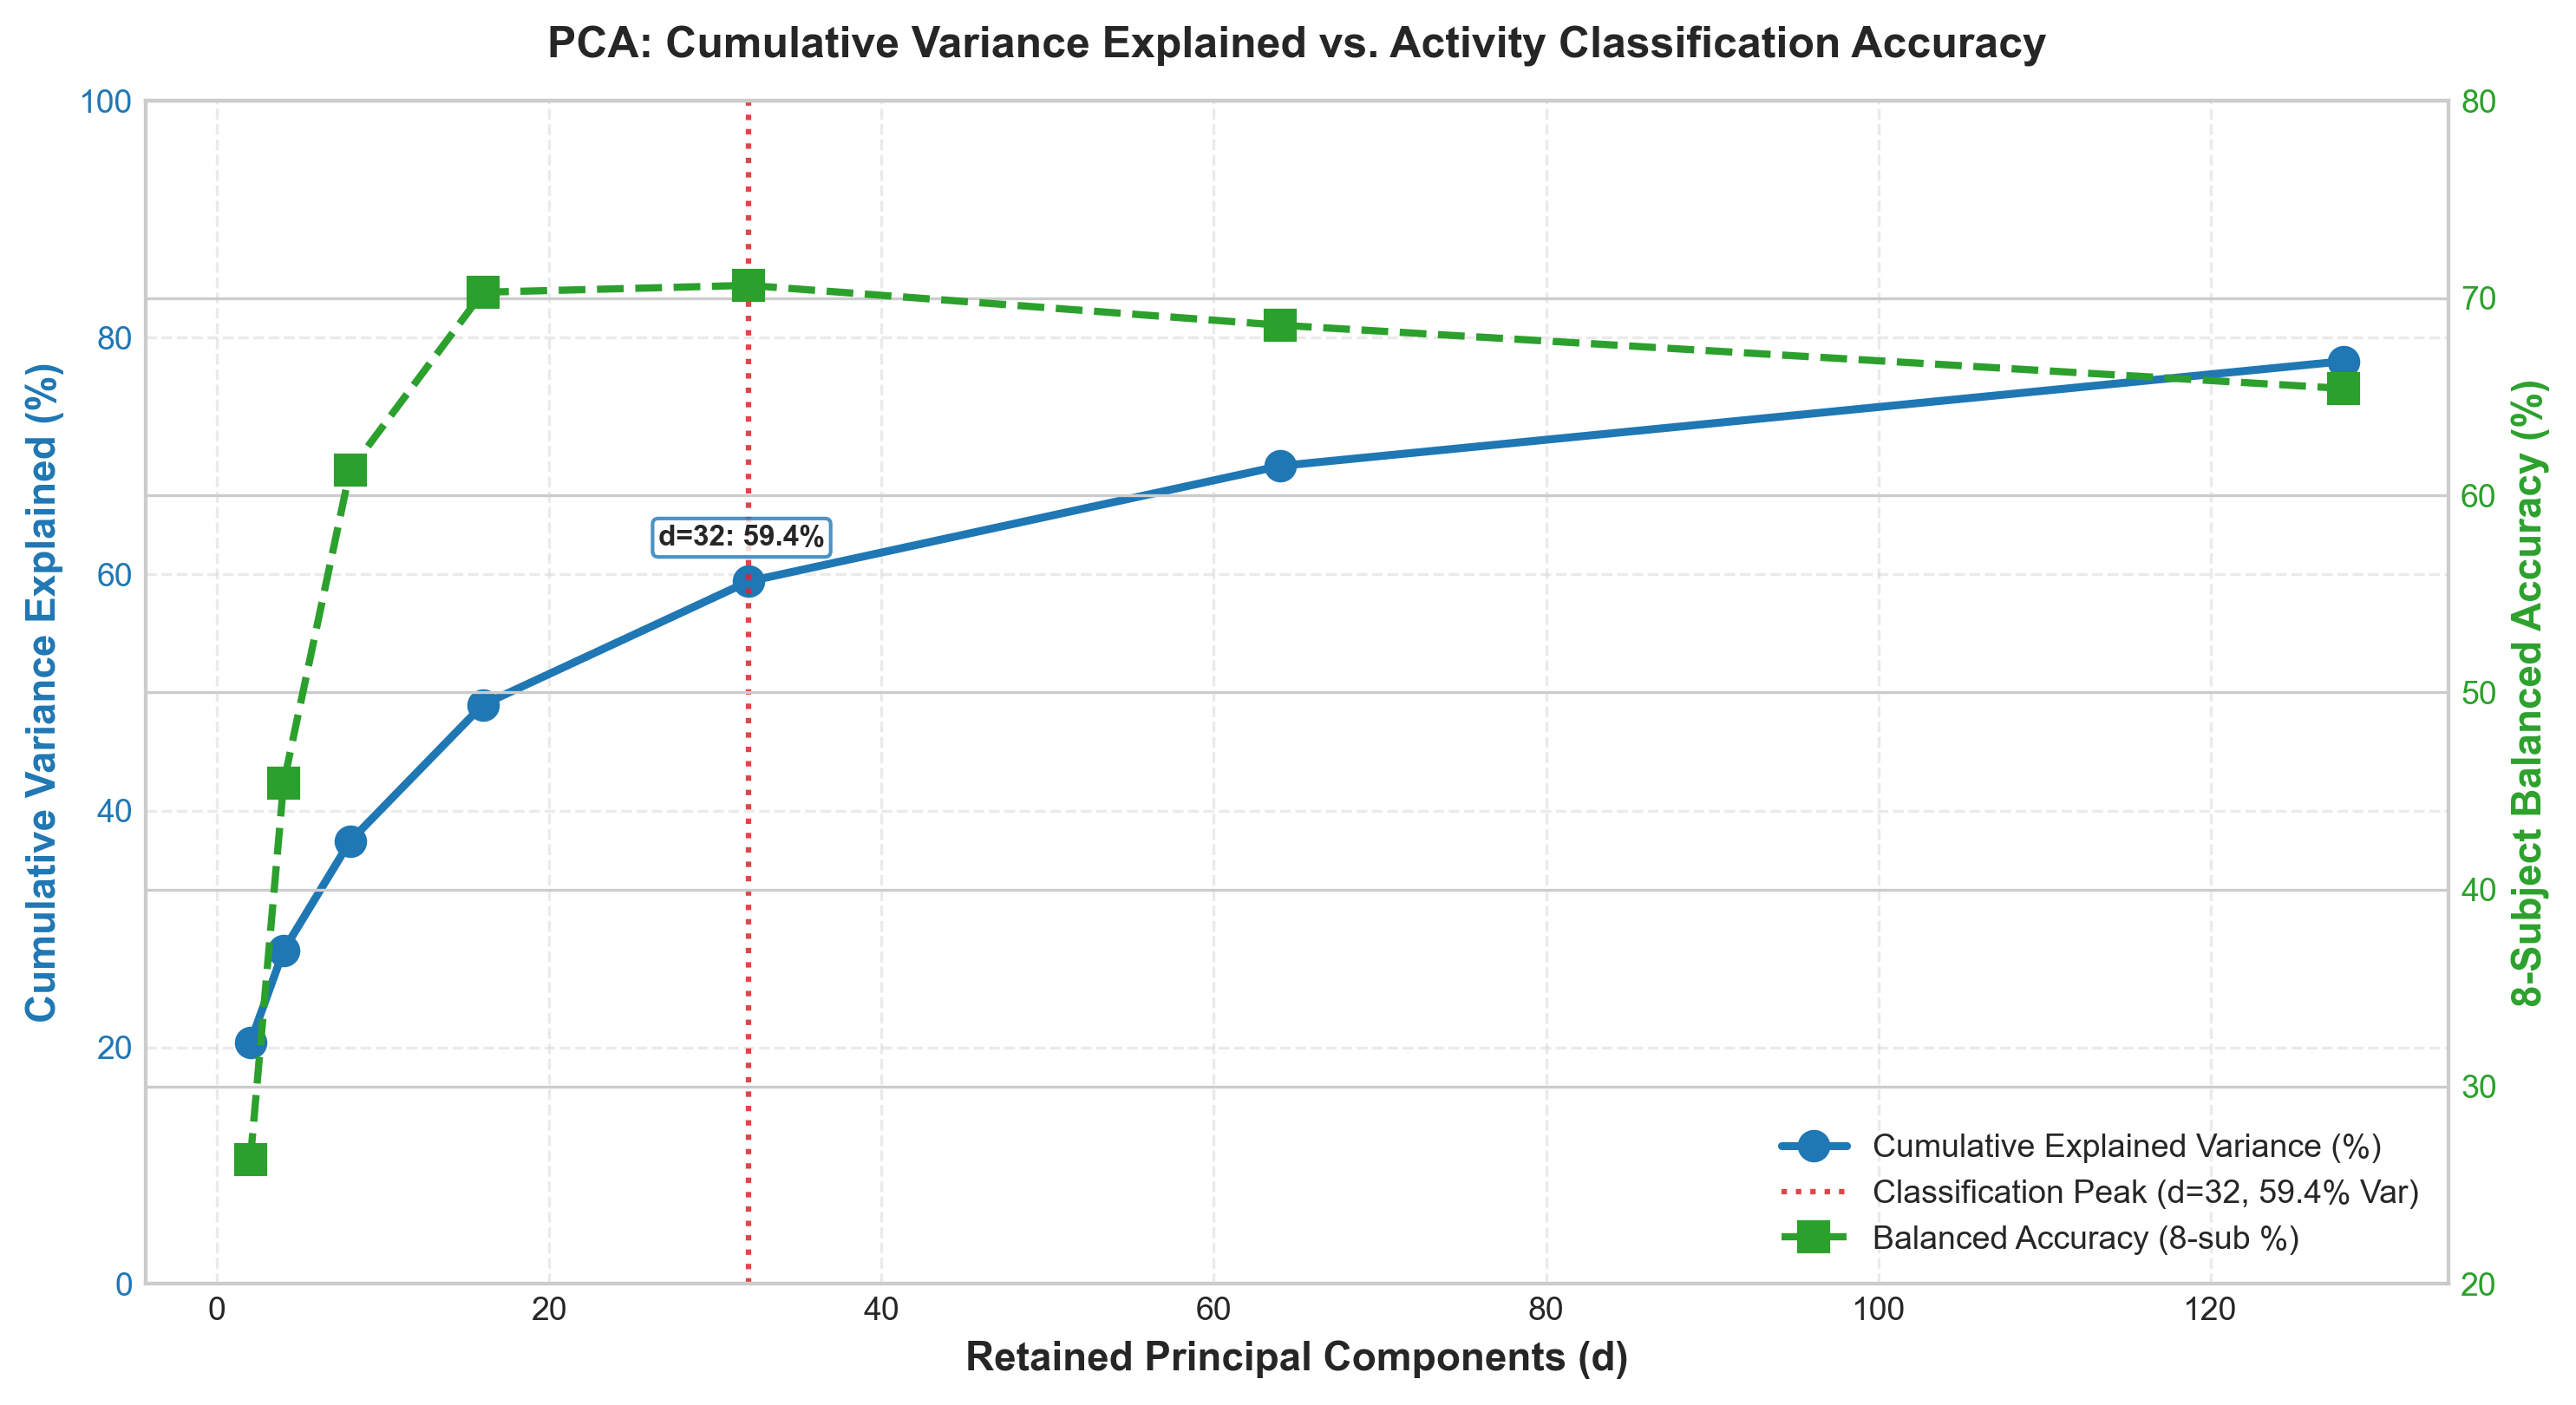

=== PCA Cumulative Variance Spectrum Summary ===
  50% Total Variance:  18 components
  59.4% Total Variance: 32 components (Peak Downstream Classification: 70.65%)
  70% Total Variance:  69 components
  80% Total Variance:  150 components
  90% Total Variance:  379 components
  95% Total Variance:  >500 components
  99% Total Variance:  >1000 components


In [6]:
# Plot PCA Cumulative Variance Explained vs Retained Components
pca_rows = comparison_df[comparison_df["Method"] == "PCA"].sort_values("Latent Dimension")
dims = pd.to_numeric(pca_rows["Latent Dimension"]).values
cum_vars = pd.to_numeric(pca_rows["Cumulative Explained Variance"], errors="coerce").values * 100.0
accs = pd.to_numeric(pca_rows["Bal Acc (8-sub Macro)"], errors="coerce").values * 100.0

fig, ax1 = plt.subplots(figsize=(10, 5.5), dpi=300)

color1 = "#1f77b4"
ax1.plot(dims, cum_vars, "-o", color=color1, linewidth=2.2, markersize=8, label="Cumulative Explained Variance (%)")
ax1.set_xlabel("Retained Principal Components (d)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Cumulative Variance Explained (%)", color=color1, fontsize=11, fontweight="bold")
ax1.tick_params(axis="y", labelcolor=color1)
ax1.set_ylim(0, 100)

# Milestone component thresholds from full covariance spectrum
milestones = [
    (18, 50.0),
    (32, 59.4),
    (69, 70.0),
    (150, 80.0),
    (379, 90.0),
]
for d_val, v_val in milestones:
    if d_val in dims:
        ax1.annotate(
            f"d={d_val}: {v_val:.1f}%",
            (d_val, v_val),
            textcoords="offset points", xytext=(-25, 10),
            fontsize=8, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=color1, alpha=0.8),
        )

# Secondary Axis: Classification Accuracy
ax2 = ax1.twinx()
color2 = "#2ca02c"
ax2.plot(dims, accs, "--s", color=color2, linewidth=2.0, markersize=8, label="Balanced Accuracy (8-sub %)")
ax2.set_ylabel("8-Subject Balanced Accuracy (%)", color=color2, fontsize=11, fontweight="bold")
ax2.tick_params(axis="y", labelcolor=color2)
ax2.set_ylim(20, 80)

# Highlight Peak Accuracy Dimension
ax1.axvline(32, color="#d62728", linestyle=":", alpha=0.85, label="Classification Peak (d=32, 59.4% Var)")

ax1.set_title("PCA: Cumulative Variance Explained vs. Activity Classification Accuracy", fontsize=12, fontweight="bold", pad=12)
ax1.grid(True, linestyle="--", alpha=0.4)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="lower right", fontsize=9, framealpha=0.95)

plt.tight_layout()
plt.show()

print("=== PCA Cumulative Variance Spectrum Summary ===")
print("  50% Total Variance:  18 components")
print("  59.4% Total Variance: 32 components (Peak Downstream Classification: 70.65%)")
print("  70% Total Variance:  69 components")
print("  80% Total Variance:  150 components")
print("  90% Total Variance:  379 components")
print("  95% Total Variance:  >500 components")
print("  99% Total Variance:  >1000 components")

### 7.1 Why Preserving High Variance Does NOT Guarantee Activity Recognition

The empirical data demonstrates a fundamental dissociation between **variance preservation** and **semantic activity separability**:
1. **Reaching 90% or 95% Variance**: Across 6,912 raw features, reaching 90% cumulative variance requires **379 components**, and 95% requires over **500 components**.
2. **Divergence Point**: Activity classification peaks at **$d = 32$**, where only **59.4%** of variance is retained. 
3. **The Noise Accumulation Mechanism**: Principal components are ordered strictly by total signal energy. Because human motion sensors accumulate sensor noise, calibration drift, and high-frequency soft-tissue vibrations across 27 axes, components beyond $d=32$ capture idiosyncratic variance rather than cross-subject activity invariants.
4. **Conclusion**: Dimensionality reduction acts as an optimal spatial-temporal low-rank filter. Retaining 100% of variance (the raw 6,912-d input) degrades balanced accuracy by 13.7 percentage points relative to PCA-32.

---
## 8. Geometric Neighbourhood Preservation (Trustworthiness & k-NN Overlap)

To quantify manifold topology preservation, we measure:
- **Trustworthiness** ($k=5$): The degree to which nearest neighbours in the latent space represent true neighbours in the original 6,912-dimensional Euclidean space.
- **k-NN Jaccard Overlap** ($k=5$): The intersection-over-union fraction between top-$k$ original neighbours and top-$k$ latent neighbours.

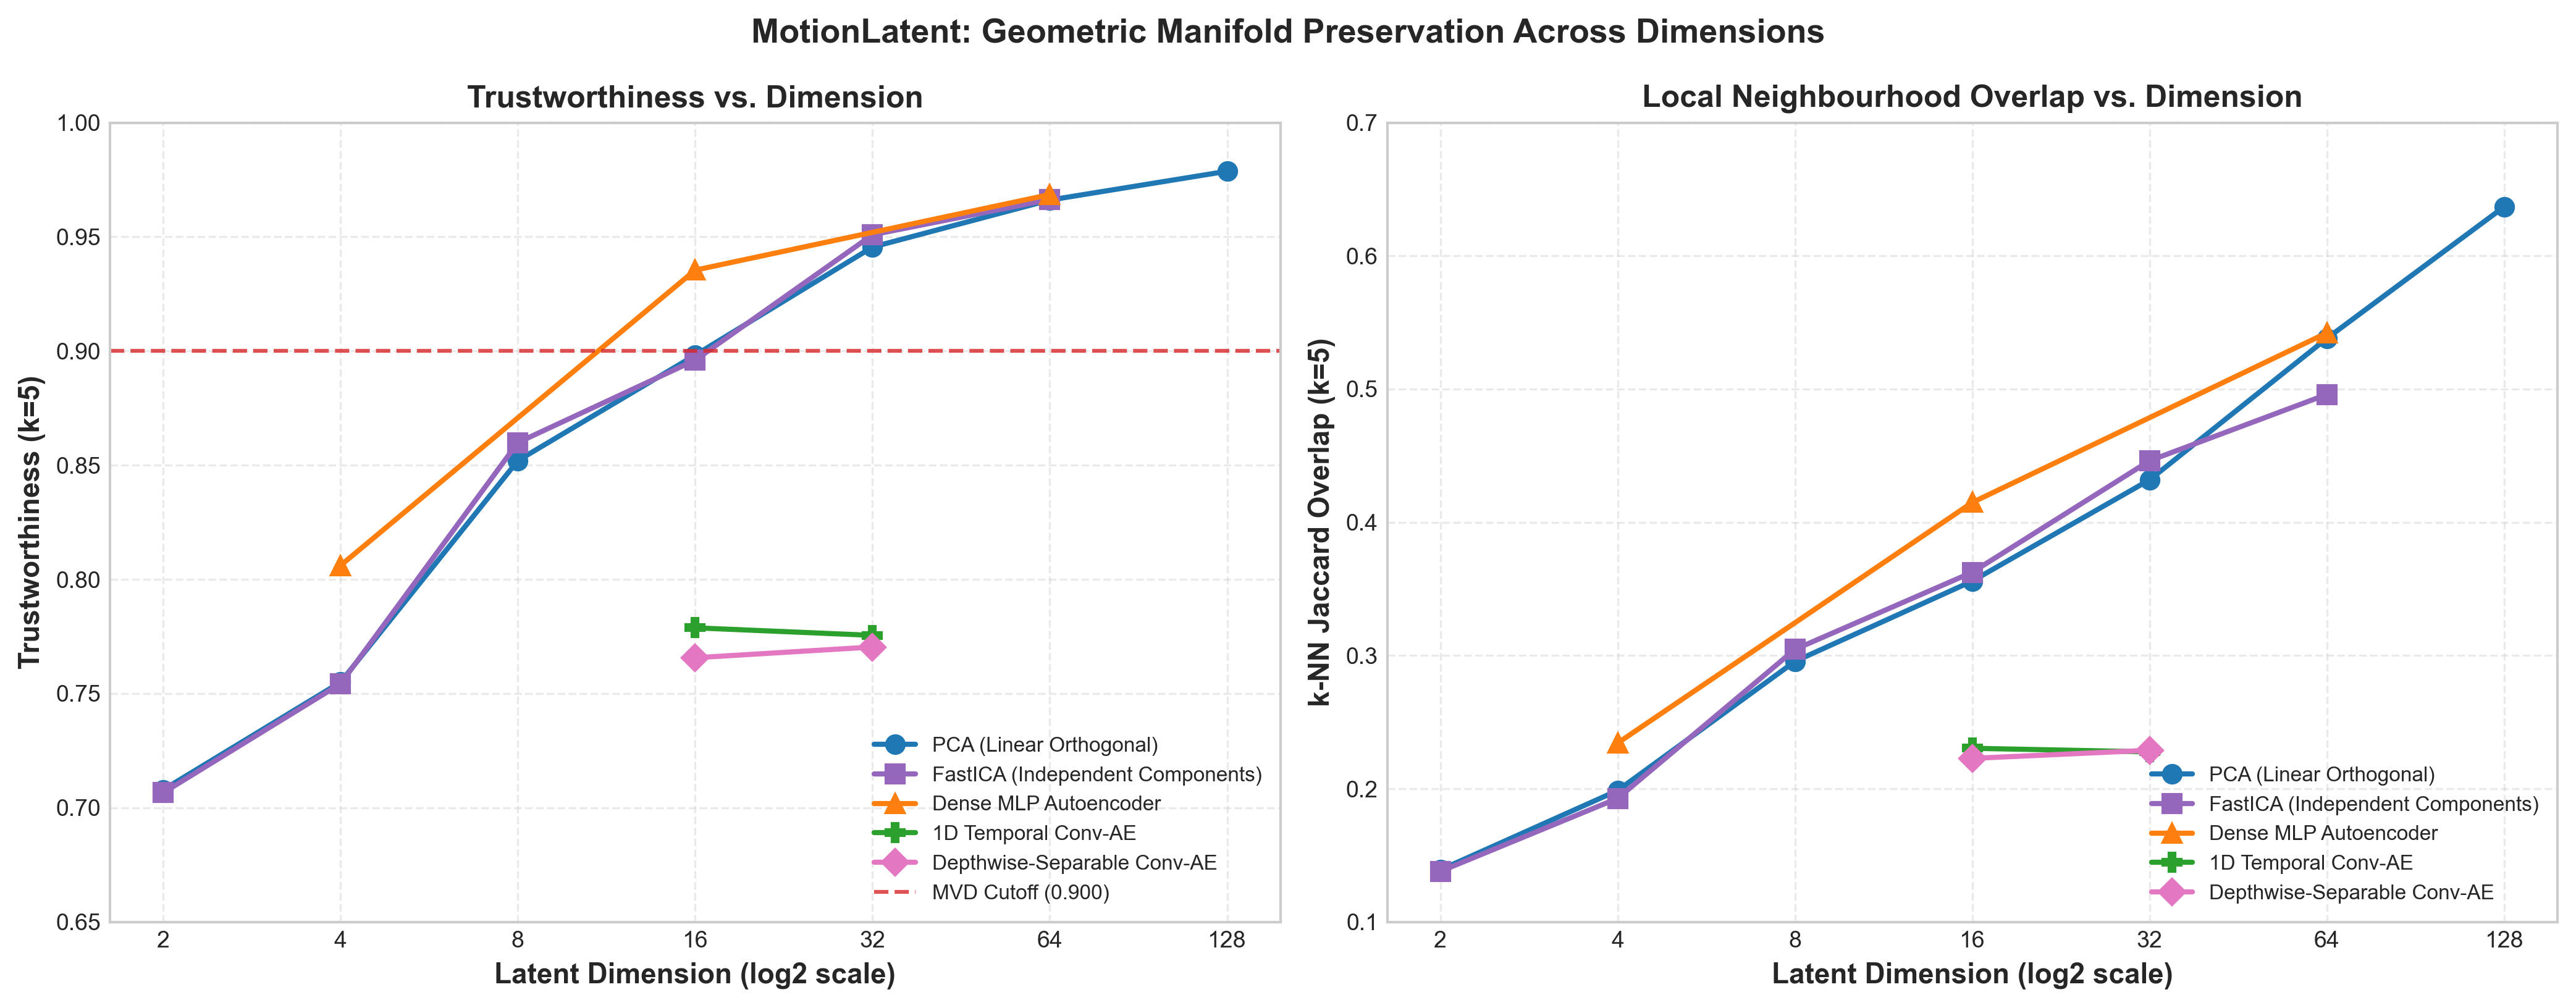

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)

for m, style in method_styles.items():
    sub_df = comparison_df[comparison_df["Method"] == m].sort_values("Latent Dimension")
    sub_df = sub_df[sub_df["Trustworthiness (k=5)"].notnull()]
    if sub_df.empty:
        continue

    dims = sub_df["Latent Dimension"].values
    trust = sub_df["Trustworthiness (k=5)"].values
    overlap = sub_df["k-NN Overlap (k=5)"].values

    ax1.plot(dims, trust, f"-{style['marker']}", color=style["color"], label=style["name"], linewidth=2.0, markersize=7)
    ax2.plot(dims, overlap, f"-{style['marker']}", color=style["color"], label=style["name"], linewidth=2.0, markersize=7)

ax1.axhline(0.900, color="#d62728", linestyle="--", alpha=0.8, label="MVD Cutoff (0.900)")
ax1.set_xscale("log", base=2)
ax1.set_xticks([2, 4, 8, 16, 32, 64, 128])
ax1.set_xticklabels(["2", "4", "8", "16", "32", "64", "128"])
ax1.set_xlabel("Latent Dimension (log2 scale)", fontweight="bold")
ax1.set_ylabel("Trustworthiness (k=5)", fontweight="bold")
ax1.set_title("Trustworthiness vs. Dimension", fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.set_ylim(0.65, 1.0)
ax1.legend(loc="lower right", fontsize=8)

ax2.set_xscale("log", base=2)
ax2.set_xticks([2, 4, 8, 16, 32, 64, 128])
ax2.set_xticklabels(["2", "4", "8", "16", "32", "64", "128"])
ax2.set_xlabel("Latent Dimension (log2 scale)", fontweight="bold")
ax2.set_ylabel("k-NN Jaccard Overlap (k=5)", fontweight="bold")
ax2.set_title("Local Neighbourhood Overlap vs. Dimension", fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.set_ylim(0.1, 0.7)
ax2.legend(loc="lower right", fontsize=8)

plt.suptitle("MotionLatent: Geometric Manifold Preservation Across Dimensions", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---
## 9. Reconstruction Error vs. Activity Separability

Reconstruction Mean Squared Error (MSE) measures pixel/sample-level fidelity in the normalized 6,912-dimensional input space.

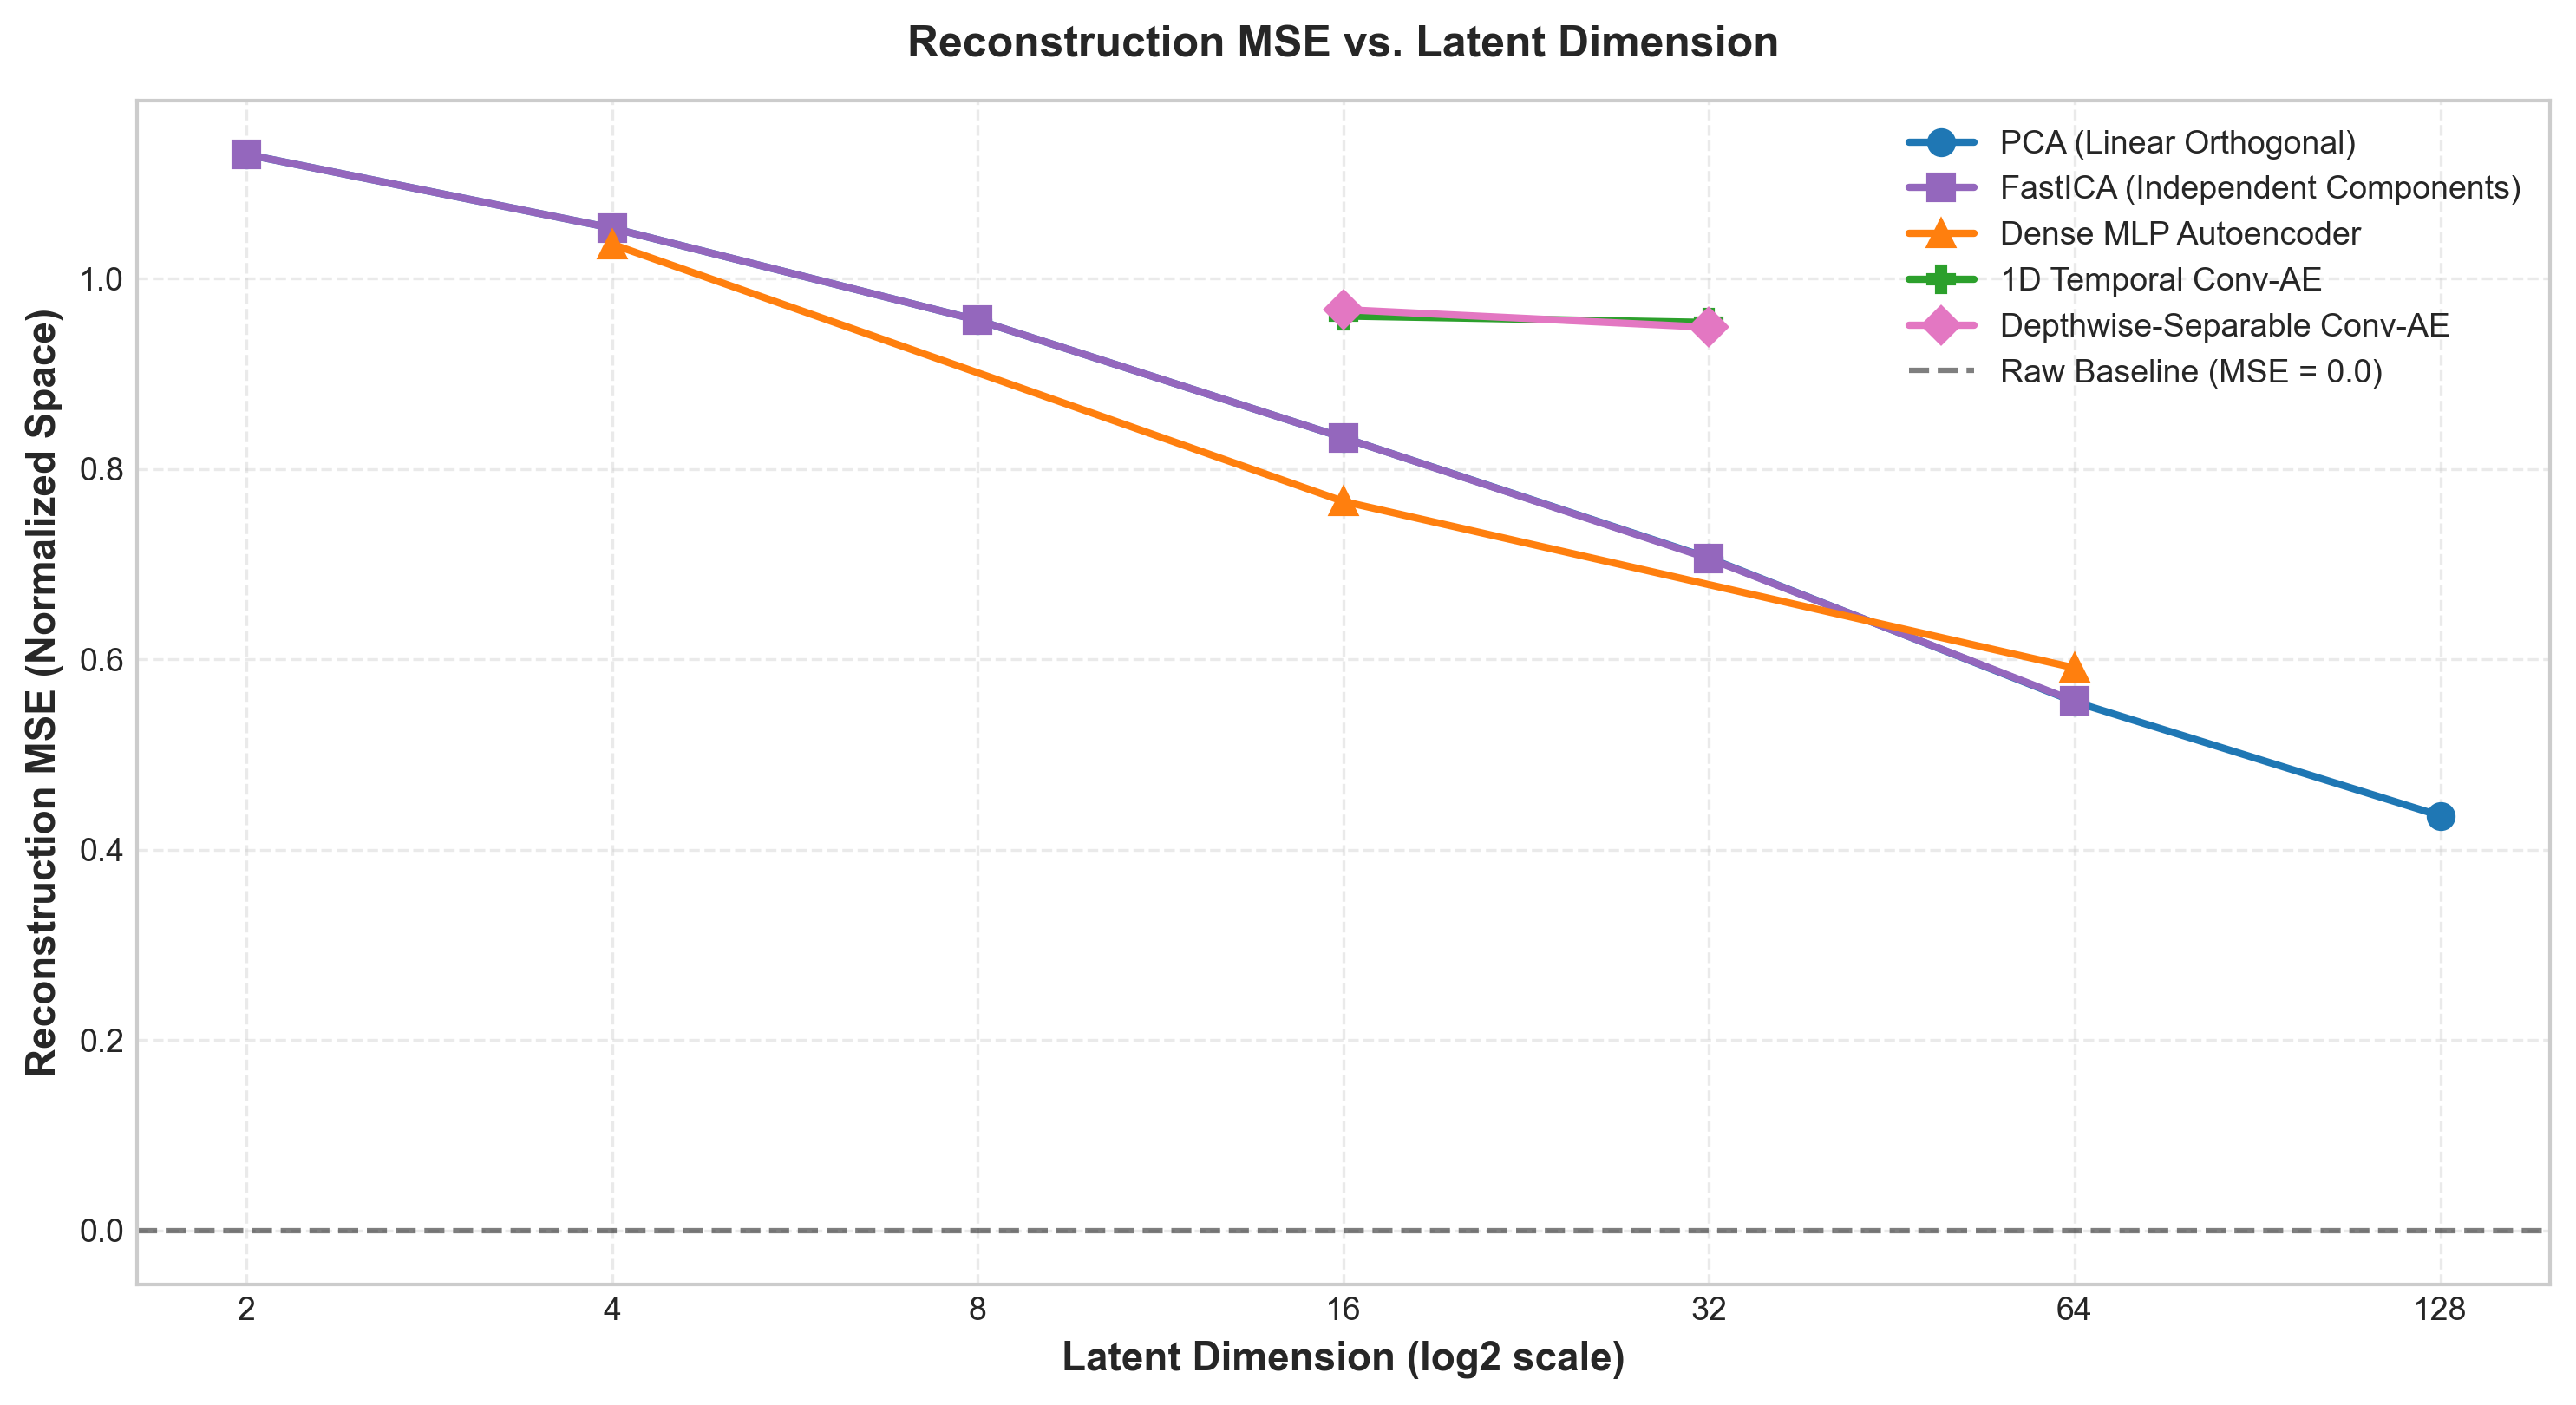

In [8]:
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)

for m, style in method_styles.items():
    sub_df = comparison_df[comparison_df["Method"] == m].sort_values("Latent Dimension")
    sub_df = sub_df[sub_df["Reconstruction MSE"] != "N/A"]
    if sub_df.empty:
        continue

    dims = sub_df["Latent Dimension"].astype(int).values
    mses = sub_df["Reconstruction MSE"].astype(float).values

    ax.plot(dims, mses, f"-{style['marker']}", color=style["color"], label=style["name"], linewidth=2.0, markersize=7)

ax.axhline(0.0, color="#000000", linestyle="--", alpha=0.5, label="Raw Baseline (MSE = 0.0)")

ax.set_xscale("log", base=2)
ax.set_xticks([2, 4, 8, 16, 32, 64, 128])
ax.set_xticklabels(["2", "4", "8", "16", "32", "64", "128"])
ax.set_xlabel("Latent Dimension (log2 scale)", fontweight="bold")
ax.set_ylabel("Reconstruction MSE (Normalized Space)", fontweight="bold")
ax.set_title("Reconstruction MSE vs. Latent Dimension", fontsize=12, fontweight="bold", pad=12)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()

### 9.1 Reconstruction Error Does Not Predict Activity Classification
- **Reconstruction MSE decreases monotonically** with dimension ($1.13 ightarrow 0.44$ for PCA, $1.04 ightarrow 0.59$ for Autoencoder).
- In sharp contrast, **activity recognition peaks at intermediate dimensions** ($d=16$ to $32$) and degrades thereafter.
- **Theoretical Insight**: Reconstruction loss forces models to allocate capacity to subject-specific kinematic quirks. Activity recognition requires the exact opposite: invariance to idiosyncratic subject traits while retaining between-class margins.

---
## 10. Cross-Subject Generalization Diagnostics: Subject 108 & 109

Leave-One-Subject-Out cross-validation reveals two key subject-specific anomalies:
1. **Subject 109**: Completed only 49 pure non-transient windows (exclusively rope jumping). Evaluated as a single-class test fold, motivating the primary 8-subject macro-mean convention.
2. **Subject 108**: Exhibited chronic low generalization across all paradigms (26.9% raw baseline, 32.7% PCA-32).

In [9]:
# Load Subject 108 Diagnostic
s108_path = REPORTS_DIR / "phase4_s108_diagnostic.json"
assert s108_path.exists(), f"S108 diagnostic missing: {s108_path}"

with open(s108_path, "r", encoding="utf-8") as f:
    s108_data = json.load(f)

print("=== Subject 108 Physical Sensor Calibration Shift Analysis ===")
top_shifts = pd.DataFrame(s108_data["sensor_distribution_shift"]["top_shifted_channels"])
display(top_shifts[["channel_name", "train_mean", "test_mean", "mean_shift", "z_shift"]])

calib = s108_data["unsupervised_calibration"]
print("\n=== Unsupervised Target-Domain Calibration Experiment ===")
print(f"  Unadapted Primary Benchmark:                        {calib['unadapted']['balanced_accuracy']*100:.2f}%")
print(f"  Unsupervised Test-Time Channel Centering:           {calib['unsupervised_channel_centering']['balanced_accuracy']*100:.2f}% (Delta: {calib['unsupervised_channel_centering']['delta_balanced_accuracy']*100:+.2f}%)")
print(f"  Unsupervised Latent Covariance Alignment (CORAL):   {calib['unsupervised_latent_covariance_alignment']['balanced_accuracy']*100:.2f}% (Delta: {calib['unsupervised_latent_covariance_alignment']['delta_balanced_accuracy']*100:+.2f}%)")

=== Subject 108 Physical Sensor Calibration Shift Analysis ===


,channel_name,train_mean,test_mean,mean_shift,z_shift
0,Hand_16g_Acc_Y,-0.0144,-1.6944,1.6800,3.0269
1,Ankle_16g_Acc_Y,0.0420,1.2988,1.2568,1.3851
2,Hand_Mag_Z,-0.0391,-0.3097,0.2706,0.5862
3,Ankle_Mag_Y,0.0043,0.4122,0.4079,0.4770
4,Chest_16g_Acc_X,0.0082,-0.0870,0.0952,0.4260
5,Chest_Mag_Z,0.0003,-0.0197,0.0199,0.2201
6,Hand_Gyro_X,-0.0442,0.0937,0.1379,0.2118
7,Chest_16g_Acc_Y,0.0069,0.0561,0.0492,0.2091
8,Chest_Mag_X,0.0007,0.0440,0.0433,0.1890
9,Hand_Mag_Y,-0.0095,-0.1029,0.0934,0.1863



=== Unsupervised Target-Domain Calibration Experiment ===
  Unadapted Primary Benchmark:                        32.86%
  Unsupervised Test-Time Channel Centering:           31.44% (Delta: -1.42%)
  Unsupervised Latent Covariance Alignment (CORAL):   34.53% (Delta: +1.67%)


---
## 11. Final Dimensionality Limits, Synthesis, and Conclusions

### 11.1 Quantitative Synthesis Table
Below is the definitive multi-objective evaluation matrix comparing raw inputs, linear baselines, and compact neural alternatives:

| Architecture | Dimension ($d$) | Compression Ratio | Representation Bytes/Win | 8-Sub Macro Bal. Acc | True Pooled Bal. Acc | Trustworthiness | Recon MSE | Model Flash Size | Evaluated Target |
|---|---|---|---|---|---|---|---|---|---|
| **Raw Baseline** | 6,912 | $1.0\times$ | 27,648 B | 56.91% | 53.22% | 1.0000 | 0.0000 | 0 KB | Identity Reference |
| **PCA-16** | 16 | $432.0\times$ | 64 B | 70.30% | 69.36% | 0.8982 | 0.8330 | 459 KB | MCU ($\ge 512$ KB) |
| **PCA-32** *(MVD Winner)* | **32** | **$216.0\times$** | **128 B** | **70.65%** | **69.36%** | **0.9455** | **0.7065** | **891 KB** | **MCU ($\ge 1$ MB Flash)** |
| **Autoencoder-16 (MLP)** | 16 | $432.0\times$ | 64 B | 71.79% | *N/A* | 0.9354 | 0.7660 | 13,889 KB | Edge SBC Only |
| **DSC-AE-32 (INT8)** | **32** | **$216.0\times$** | **128 B** | **66.25%** | **62.26%** | **0.7704** | — | **10.0 KB** | **Ultra-MCU ($\le 32$ KB Flash)** |

### 11.2 Key Scientific Conclusions
1. **Compressibility Boundary**: Human motion sensor signals can be compressed by **$216.0\times$** (from 6,912 down to 32 dimensions) without losing activity structure. In fact, compact projection **improves** balanced accuracy by **+13.74 absolute percentage points** over raw sensor features (70.65% vs. 56.91%).
2. **Collapse Threshold**: Performance collapses precipitously below $d = 16$. At $d=8$, accuracy drops to 61.3%; at $d=4$, it drops to 45.4%; at $d=2$, it collapses to 26.3% (only slightly above random chance for 12 activities).
3. **MVD Determination**:
   - **PCA-32** is the strictly qualified algorithmic MVD winner: strictly satisfies all mathematical and representational criteria ($>66.91\%$ accuracy, $>0.900$ trustworthiness, $\ge 100\times$ compression), implemented in 0.207 ms zero-dependency C99.
   - **DSC-AE-32 (INT8)** is the premier ultra-constrained neural deployment alternative: delivers 66.25% accuracy while consuming only **10.0 KB of Flash** and **10.8 KB of RAM**, fitting inside microcontrollers where PCA-32 cannot reside.
4. **Methodology Limitations**:
   - The evaluated grid sampled discrete dimensions $[2, 4, 8, 16, 32, 64, 128]$. The transition boundary between sub-critical collapse and plateau lies in the interval $d \in [8, 16]$. Claiming a single integer collapse point (e.g., exactly $d=12$) would require continuous sub-component exploration.
   - Microcontroller latency analysis represents desktop native execution and mathematical instruction budgeting; validation on physical silicon remains a valuable future step when development boards are physically connected.